# 13 — Matrix-free measurement mitigation with `mthree` (M3)

Qubit readout is one of the noisiest operations on current hardware. A qubit prepared in $|1\rangle$ is sometimes
reported as `0`, and the reverse also happens. These **readout errors** (measurement errors) bias each histogram and each
expectation value computed from it.

**M3** (*matrix-free measurement mitigation*) corrects readout errors at low cost. It does not invert the full
$2^N\times 2^N$ assignment matrix. It works only in the small subspace of bitstrings that appear in the experiment
([Basic usage](https://qiskit.github.io/qiskit-addon-mthree/basic.html) [1]).

The `mthree` package (version 3.0.0 here) provides:

| object | purpose |
|---|---|
| [`mthree.M3Mitigation(backend)`](https://qiskit.github.io/qiskit-addon-mthree/stubs/mthree.M3Mitigation.html) [10] | the mitigator: it runs calibration circuits (`cals_from_system`) and corrects counts (`apply_correction`) |
| [`QuasiDistribution`](https://qiskit.github.io/qiskit-addon-mthree/stubs/mthree.classes.QuasiDistribution.html) [11] / `QuasiCollection` | mitigated quasi-probabilities with `expval`, `stddev`, `expval_and_stddev` and `nearest_probability_distribution` |
| `mthree.utils` | helper functions: [`final_measurement_mapping`](https://qiskit.github.io/qiskit-addon-mthree/stubs/mthree.utils.final_measurement_mapping.html) [12], `marginal_distribution`, `expval`, `stddev`, ... |

In version 3.0, the companion package `runningman` handles the backends. It is installed as a dependency.
Simulator backends such as Aer are used directly. This notebook needs only a simulator.

**Based on** (`mthree` documentation)

* [Basic usage](https://qiskit.github.io/qiskit-addon-mthree/basic.html) [1] and [Using M3 with transpiled circuits](https://qiskit.github.io/qiskit-addon-mthree/transpiled.html) [2] (Sections 3–4)
* [Obtaining expectation values](https://qiskit.github.io/qiskit-addon-mthree/expvals.html) [3] and [Error analysis](https://qiskit.github.io/qiskit-addon-mthree/error.html) [4] (Section 5)
* [Advanced usage](https://qiskit.github.io/qiskit-addon-mthree/advanced.html) [5] (Section 6: solvers and Hamming distance)
* [Balanced calibrations](https://qiskit.github.io/qiskit-addon-mthree/balanced.html) [6] and [Saving and loading calibration data](https://qiskit.github.io/qiskit-addon-mthree/cal_io.html) [7] (Section 7)
* [Converting to probabilities](https://qiskit.github.io/qiskit-addon-mthree/probs.html) [8] (Section 4) and [Using distribution collections](https://qiskit.github.io/qiskit-addon-mthree/collections.html) [9] (Section 8)

The examples (GHZ states, the solver timing scan and the parameter sweep) are our own.

```bash
pip install mthree
```

All cells run on a noisy Aer simulator built from the fake backend `FakeTorino` (133 qubits). The fake backend provides the
noise model and the transpilation target.

## 0. Setup

In [1]:
import os, time, tempfile, warnings
import numpy as np
import matplotlib.pyplot as plt
from functools import reduce

import qiskit, qiskit_aer, mthree
from qiskit import QuantumCircuit, transpile
from qiskit.circuit import Parameter
from qiskit.quantum_info import Statevector
from qiskit_aer import AerSimulator
from qiskit_aer.primitives import SamplerV2 as AerSamplerV2
from qiskit_ibm_runtime.fake_provider import FakeTorino
from importlib.metadata import version

print("qiskit", qiskit.__version__, "| qiskit-aer", qiskit_aer.__version__,
      "| mthree", mthree.__version__, "| runningman", version("runningman"))
mthree.about()

# colors: mitigated / raw / ideal (fixed order throughout the notebook)
C_MIT, C_RAW, C_IDEAL = "#2a78d6", "#eb6834", "#1baf7a"
plt.rcParams.update({"axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.alpha": 0.3, "figure.dpi": 100})

qiskit 2.5.2 | qiskit-aer 0.17.2 | mthree 3.0.0 | runningman 2.3.0
# Matrix-free Measurement Mitigation (M3) version 3.0.0
# (C) Copyright IBM 2021.
# Paul Nation, Hwajung Kang, Neereja Sundaresan
# Jay Gambetta, and Matthew Treinish.
# Compiled with OpenMP: True


## 1. Theory: readout errors and the assignment matrix

For a single qubit, a $2\times2$ column-stochastic **assignment matrix** describes the readout:

$$
A^{(1)} = \begin{pmatrix} P(0|0) & P(0|1) \\ P(1|0) & P(1|1) \end{pmatrix},\qquad
\text{column } j = \text{prepared state},\ \text{row } i = \text{measured outcome}.
$$

For $N$ qubits, the noisy probability vector $\tilde p$ follows from the ideal vector $p$ as $\tilde p = A\,p$. Here $A$ is a $2^N\times2^N$ matrix.
If the readout errors are uncorrelated, $A = A^{(1)}_{N-1}\otimes\cdots\otimes A^{(1)}_0$. In principle, mitigation is then $p = A^{-1}\tilde p$.

**Why this does not scale.** $A$ has $4^N$ entries, and a dense solve costs $O(8^N)$ operations. At $N=20$, $A$ needs 8 TB in float64
(see the table below). Even with a tensor-product form, $A^{-1}\tilde p$ is a dense vector of length $2^N$.

**The M3 method.** With $S$ shots, at most $S$ distinct bitstrings appear, and often far fewer. M3 restricts the problem to the
subspace spanned by the observed bitstrings $\{s\}$:

$$
\tilde A_{s s'} = \langle s|A|s'\rangle \quad\text{for observed } s,s',\qquad
\text{and solves}\quad \tilde A\, \hat p = \tilde p .
$$

Each matrix element is a product of 1-qubit calibration entries. M3 therefore computes the elements **on the fly** ("matrix-free") from $N$
small $2\times2$ matrices. Two further steps:

* M3 **renormalizes** each column of $\tilde A$ to sum to 1. This compensates for the probability outside the subspace.
* M3 can keep only the elements between bitstrings with **Hamming distance $\le d$**. Readout errors rarely flip many bits at once. The default is $d=\min(N,3)$.

The reduced system has dimension $n_{\text{obs}}\le S$, independent of $N$. M3 solves it with an LU decomposition (**direct**) or, without storing
the matrix, with preconditioned **GMRES** (**iterative**). The solution $\hat p$ is a **quasi-probability** distribution: it sums to 1, but it can have small negative entries.

In [2]:
print(f"{'N':>3} {'dim 2^N':>12} {'full A (float64)':>18} {'M3 dim (<= shots=1e4)':>22}")
for N in [5, 10, 15, 20, 30, 50]:
    mem = 4.0**N * 8
    unit = ["B", "KB", "MB", "GB", "TB", "PB", "EB", "ZB", "YB"]
    k = min(int(np.log(mem) / np.log(1024)), len(unit) - 1)
    print(f"{N:>3} {2**N:>12.3g} {mem/1024**k:>14.3g} {unit[k]:<3} {min(2**N, 10_000):>22}")

  N      dim 2^N   full A (float64)  M3 dim (<= shots=1e4)
  5           32              8 KB                      32
 10     1.02e+03              8 MB                    1024
 15     3.28e+04              8 GB                   10000
 20     1.05e+06              8 TB                   10000
 30     1.07e+09              8 EB                   10000
 50     1.13e+15       8.39e+06 YB                   10000


## 2. A noisy "device": Aer from a fake backend

`AerSimulator.from_backend(FakeTorino())` copies the coupling map, the basis gates and a noise model from the calibration
snapshot of the backend. The noise model includes **readout errors per qubit**. M3 reads `backend.configuration()` to get the number of qubits,
the maximum number of shots, and whether the target is a simulator. Here it is a simulator, so the default calibration method is `"independent"`.

We use the CPU with two threads. The GPU (`device="GPU"`) also works, but these noisy circuits are small.

aer_simulator_from(fake_torino) | qubits: 133 | devices: ('CPU', 'GPU')
readout error per qubit: median 2.295%, mean 4.674%, worst 56.5% (qubit 86)


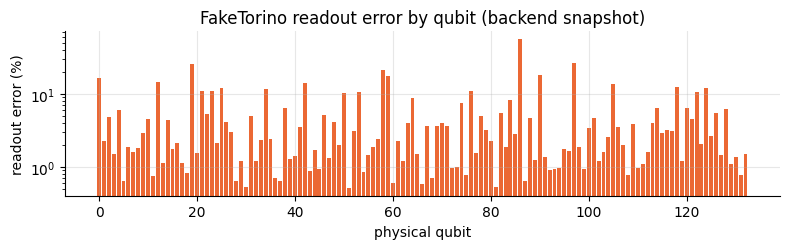

In [3]:
fake = FakeTorino()
sim = AerSimulator.from_backend(fake, max_parallel_threads=2, seed_simulator=1234)
print(sim.name, "| qubits:", sim.num_qubits, "| devices:", sim.available_devices())

ro_err = np.array([fake.target["measure"][(q,)].error for q in range(fake.num_qubits)])
print(f"readout error per qubit: median {np.median(ro_err):.3%}, mean {ro_err.mean():.3%}, worst {ro_err.max():.1%} (qubit {ro_err.argmax()})")

fig, ax = plt.subplots(figsize=(8, 2.6))
ax.bar(range(fake.num_qubits), ro_err * 100, color=C_RAW, width=0.8)
ax.set_yscale("log"); ax.set_xlabel("physical qubit"); ax.set_ylabel("readout error (%)")
ax.set_title("FakeTorino readout error by qubit (backend snapshot)")
plt.tight_layout(); plt.show()

## 3. Calibration and the assignment matrix

This section follows [Basic usage](https://qiskit.github.io/qiskit-addon-mthree/basic.html) [1] and [Using M3 with transpiled circuits](https://qiskit.github.io/qiskit-addon-mthree/transpiled.html) [2].

`M3Mitigation(system)` only stores the backend. `cals_from_system(qubits, shots, method)` builds the calibration circuits and runs them.
It stores one $2\times 2$ matrix per calibrated qubit in `mit.single_qubit_cals`. Notes:

* Calibrate only the measured qubits. `cals_from_system` accepts a **final-measurement mapping** `{classical bit: physical qubit}`.
  [`mthree.utils.final_measurement_mapping(transpiled_circuit)`](https://qiskit.github.io/qiskit-addon-mthree/stubs/mthree.utils.final_measurement_mapping.html) [12] returns this mapping after transpilation.
* The default is `async_cal=True`: the jobs run in a background thread. The first access to `single_qubit_cals` (or `apply_correction`)
  waits for them. We use `async_cal=False`, so that the timings include the calibration.
* `readout_fidelity(qubits)` returns $\tfrac12[P(0|0)+P(1|1)]$ for each qubit.

The first example is a 4-qubit GHZ state. For 4 qubits, the full $16\times16$ matrix $A$ is still small enough to inspect.

In [4]:
def ghz(n):
    qc = QuantumCircuit(n)
    qc.h(0)
    for i in range(n - 1):
        qc.cx(i, i + 1)
    qc.measure_all()
    return qc

ghz4 = transpile(ghz(4), sim, optimization_level=3, seed_transpiler=7)
map4 = mthree.utils.final_measurement_mapping(ghz4)
print("final measurement mapping {clbit: physical qubit}:", map4)

mit = mthree.M3Mitigation(sim)
t0 = time.perf_counter()
mit.cals_from_system(map4, shots=20_000, async_cal=False)
print(f"calibration ({mit.cal_method}) took {time.perf_counter()-t0:.2f} s")
for c, q in map4.items():
    print(f"clbit {c} <- qubit {q:3d}:  A1 =", np.array2string(mit.single_qubit_cals[q], precision=4).replace("\n", ""),
          f" fidelity {mit.readout_fidelity([q])[0]:.4f}  (backend: {1-ro_err[q]:.4f})")

final measurement mapping {clbit: physical qubit}: {0: 81, 1: 80, 2: 92, 3: 99}


calibration (independent) took 1.61 s
clbit 0 <- qubit  81:  A1 = [[0.9952 0.0052] [0.0048 0.9948]]  fidelity 0.9950  (backend: 0.9946)
clbit 1 <- qubit  80:  A1 = [[0.975  0.0232] [0.0249 0.9768]]  fidelity 0.9759  (backend: 0.9771)
clbit 2 <- qubit  92:  A1 = [[0.9905 0.0101] [0.0095 0.9899]]  fidelity 0.9902  (backend: 0.9910)
clbit 3 <- qubit  99:  A1 = [[0.9911 0.0098] [0.0089 0.9902]]  fidelity 0.9907  (backend: 0.9905)


The full assignment matrix for the 4 measured qubits is the tensor product of the four $A^{(1)}$. The bitstrings use Qiskit order: clbit 0 is
the rightmost bit, so the matrix for clbit 0 is the rightmost Kronecker factor.

* Almost all of the weight is on the diagonal.
* The first off-diagonal bands are single bit flips (Hamming distance 1).
* The entries decrease quickly with the Hamming distance. For this reason, truncation at distance $d$ is safe.

A is column stochastic: True


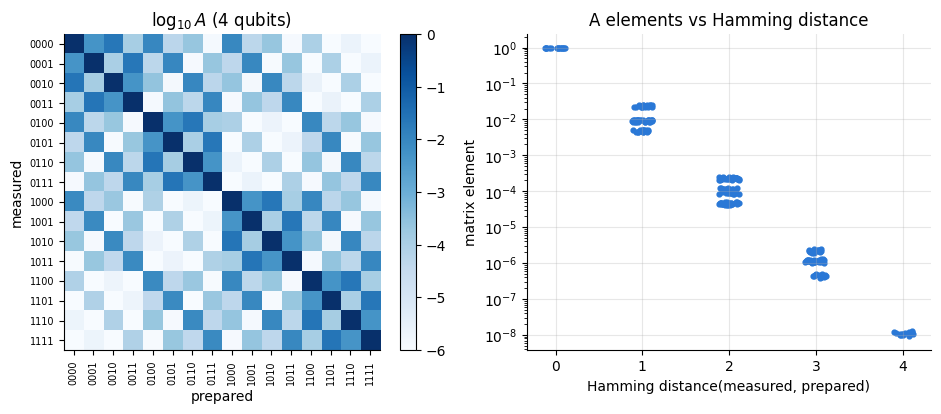

In [5]:
mats = [mit.single_qubit_cals[map4[c]] for c in sorted(map4)]          # clbit 0,1,2,3
A_full = reduce(np.kron, mats[::-1])                                     # clbit 3 (x) ... (x) clbit 0
print("A is column stochastic:", np.allclose(A_full.sum(0), 1, atol=1e-5))

fig, axs = plt.subplots(1, 2, figsize=(10, 4.2))
im = axs[0].imshow(np.log10(A_full + 1e-8), cmap="Blues", vmin=-6, vmax=0)
labels = [format(i, "04b") for i in range(16)]
axs[0].set_xticks(range(16), labels, rotation=90, fontsize=7); axs[0].set_yticks(range(16), labels, fontsize=7)
axs[0].set_xlabel("prepared"); axs[0].set_ylabel("measured"); axs[0].set_title(r"$\log_{10} A$ (4 qubits)"); axs[0].grid(False)
plt.colorbar(im, ax=axs[0], fraction=0.046)
ham = np.array([[bin(i ^ j).count("1") for j in range(16)] for i in range(16)])
for d in range(5):
    v = A_full[ham == d]
    axs[1].scatter(np.full(v.size, d) + np.random.default_rng(d).uniform(-.12, .12, v.size), v, s=12, color=C_MIT)
axs[1].set_yscale("log"); axs[1].set_xlabel("Hamming distance(measured, prepared)"); axs[1].set_ylabel("matrix element")
axs[1].set_title("A elements vs Hamming distance")
plt.tight_layout(); plt.show()

## 4. Mitigating a GHZ state: quasi-probabilities

We sample the 4-qubit GHZ circuit. Its ideal output is $\tfrac12(|0000\rangle+|1111\rangle)$. We correct the counts with `apply_correction(counts, mapping)`.
For 4 qubits the full inverse is cheap. We can therefore check that M3 with `distance=-1` (no truncation) gives the same result as $A^{-1}\tilde p$.

The result is a [`QuasiDistribution`](https://qiskit.github.io/qiskit-addon-mthree/stubs/mthree.classes.QuasiDistribution.html) [11], a `dict` that maps bitstrings to quasi-probabilities. `nearest_probability_distribution()` returns the
closest true probability distribution in the $L_2$ norm ([Converting to probabilities](https://qiskit.github.io/qiskit-addon-mthree/probs.html) [8]).

QuasiDistribution | sum = 1.0 | min = -0.00061 | L2 distance to nearest prob. dist = 0.00088
max |M3 - A^{-1} p~| over observed strings: 8.984346622220585e-08


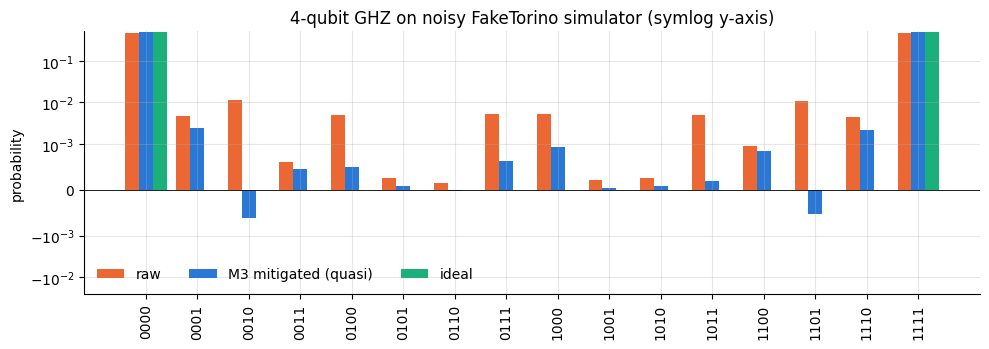

In [6]:
shots = 20_000
counts4 = sim.run(ghz4, shots=shots).result().get_counts()
quasi4 = mit.apply_correction(counts4, map4, distance=-1)
probs4, l2 = quasi4.nearest_probability_distribution(return_distance=True)
print(type(quasi4).__name__, "| sum =", round(sum(quasi4.values()), 6), "| min =", round(min(quasi4.values()), 5),
      "| L2 distance to nearest prob. dist =", round(l2, 5))

# full-matrix inversion on the observed bitstrings (valid here because all 16 strings were seen)
ptilde = np.array([counts4.get(b, 0) / shots for b in labels])
p_full = np.linalg.solve(A_full, ptilde)
print("max |M3 - A^{-1} p~| over observed strings:", max(abs(quasi4.get(b, 0) - p_full[i]) for i, b in enumerate(labels) if b in counts4))

ideal4 = Statevector(ghz(4).remove_final_measurements(inplace=False)).probabilities_dict()
fig, ax = plt.subplots(figsize=(10, 3.6))
x = np.arange(16); w = 0.27
ax.bar(x - w, [counts4.get(b, 0) / shots for b in labels], w, color=C_RAW, label="raw")
ax.bar(x, [quasi4.get(b, 0) for b in labels], w, color=C_MIT, label="M3 mitigated (quasi)")
ax.bar(x + w, [ideal4.get(b, 0) for b in labels], w, color=C_IDEAL, label="ideal")
ax.axhline(0, color="k", lw=0.6)
ax.set_xticks(x, labels, rotation=90); ax.set_ylabel("probability"); ax.set_yscale("symlog", linthresh=1e-3)
ax.set_title("4-qubit GHZ on noisy FakeTorino simulator (symlog y-axis)"); ax.legend(frameon=False, ncol=3)
plt.tight_layout(); plt.show()

M3 moves weight from the strings with one bit flip (`0001`, `1110`, ...) back to `0000` and `1111`. M3 cannot correct population that **gate**
errors (CX errors and decoherence) move to the wrong strings. Readout mitigation corrects only readout errors, so the mitigated result is not the ideal result.

## 5. A larger GHZ state: expectation values with error bars

This section follows [Obtaining expectation values](https://qiskit.github.io/qiskit-addon-mthree/expvals.html) [3] and [Error analysis](https://qiskit.github.io/qiskit-addon-mthree/error.html) [4].

Now $N=10$. The full $A$ would be a $1024\times1024$ matrix, but only 175 distinct bitstrings appear. Diagonal observables can be given in two forms:

* Pauli **Z-strings** with the characters `I`/`Z` (or the projectors `0`/`1`), in bitstring order: the leftmost character is the highest clbit;
* dicts `{bitstring: coefficient}`.

`expval_and_stddev` returns the expectation value and an **upper bound on its standard deviation**. This bound
includes the **mitigation overhead** $\gamma^2$. This factor increases the variance, and it grows with the readout error. Pass `return_mitigation_overhead=True` to get it.

For the GHZ state, $\langle Z_iZ_j\rangle = 1$ for every pair, $\langle Z^{\otimes N}\rangle = 1$ (for even $N$), and $\langle Z_i\rangle = 0$.

In [7]:
N = 10
ghzN = transpile(ghz(N), sim, optimization_level=3, seed_transpiler=7)
mapN = mthree.utils.final_measurement_mapping(ghzN)
print("physical qubits:", list(mapN.values()))

mit.cals_from_system(mapN, shots=20_000, async_cal=False)    # adds/updates cals for these qubits
countsN = sim.run(ghzN, shots=shots).result().get_counts()
quasiN, info = mit.apply_correction(countsN, mapN, return_mitigation_overhead=True, details=True)
print(f"distinct bitstrings: {len(countsN)} (of 2^{N}={2**N}) | solver: {info['method']} in {info['time']*1e3:.1f} ms"
      f" | mitigation overhead gamma^2 = {quasiN.mitigation_overhead:.3f}")

def zstr(n, qubits):
    s = ["I"] * n
    for q in qubits:
        s[n - 1 - q] = "Z"      # clbit q is character n-1-q
    return "".join(s)

ops = {r"$Z_0$": zstr(N, [0]), r"$Z_0Z_1$": zstr(N, [0, 1]), r"$Z_0Z_{9}$": zstr(N, [0, 9]),
       r"$Z_4Z_5$": zstr(N, [4, 5]), r"$Z^{\otimes 4}$": zstr(N, range(4)), r"$Z^{\otimes 10}$": "Z" * N}
ideal_vals = [0, 1, 1, 1, 1, 1]
rawN = mthree.classes.ProbDistribution(countsN)          # raw probabilities with the same API
res = {k: (rawN.expval_and_stddev(op), quasiN.expval_and_stddev(op)) for k, op in ops.items()}
print(f"{'op':>16} {'raw':>16} {'mitigated':>16} ideal")
for (k, ((r, rs), (m, ms))), iv in zip(res.items(), ideal_vals):
    print(f"{ops[k]:>16} {r:8.4f} ±{rs:.4f} {m:8.4f} ±{ms:.4f}   {iv}")

# dict-form operator: projector onto the GHZ "good" strings = population fidelity
pop = {"0" * N: 1, "1" * N: 1}
print("\nP(00..0)+P(11..1): raw", round(rawN.expval(pop), 4), "| mitigated", round(quasiN.expval(pop), 4), "| ideal 1")

physical qubits: [48, 36, 29, 28, 27, 17, 8, 7, 6, 5]


distinct bitstrings: 175 (of 2^10=1024) | solver: direct in 4.0 ms | mitigation overhead gamma^2 = 2.008
              op              raw        mitigated ideal
      IIIIIIIIIZ   0.0017 ±0.0071  -0.0015 ±0.0100   0
      IIIIIIIIZZ   0.8930 ±0.0071   0.9841 ±0.0100   1
      ZIIIIIIIIZ   0.8388 ±0.0071   0.9238 ±0.0100   1
      IIIIZZIIII   0.9059 ±0.0071   0.9876 ±0.0100   1
      IIIIIIZZZZ   0.8460 ±0.0071   0.9665 ±0.0100   1
      ZZZZZZZZZZ   0.6621 ±0.0071   0.9371 ±0.0100   1

P(00..0)+P(11..1): raw 0.8024 | mitigated 0.9516 | ideal 1


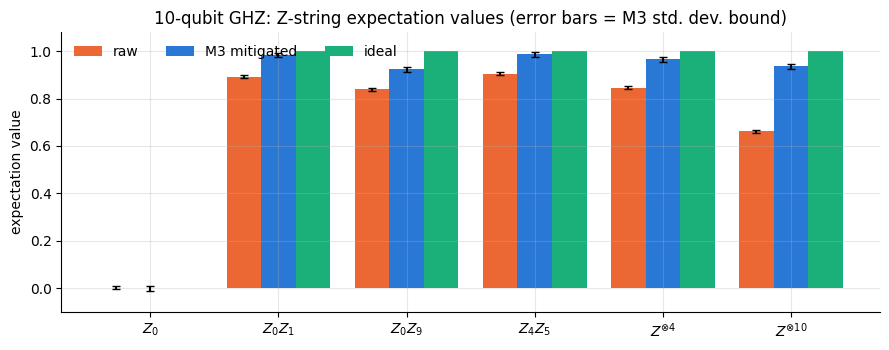

In [8]:
fig, ax = plt.subplots(figsize=(9, 3.6))
x = np.arange(len(ops)); w = 0.27
r_v = [v[0][0] for v in res.values()]; r_e = [v[0][1] for v in res.values()]
m_v = [v[1][0] for v in res.values()]; m_e = [v[1][1] for v in res.values()]
ax.bar(x - w, r_v, w, yerr=r_e, color=C_RAW, capsize=3, label="raw")
ax.bar(x, m_v, w, yerr=m_e, color=C_MIT, capsize=3, label="M3 mitigated")
ax.bar(x + w, ideal_vals, w, color=C_IDEAL, label="ideal")
ax.set_xticks(x, list(ops)); ax.set_ylabel("expectation value"); ax.set_ylim(-0.1, 1.08)
ax.set_title(f"{N}-qubit GHZ: Z-string expectation values (error bars = M3 std. dev. bound)")
ax.legend(frameon=False, ncol=3, loc="upper left", bbox_to_anchor=(0, 1.0))
plt.tight_layout(); plt.show()

**Check of the error bars.** We repeat the experiment 12 times with different simulator seeds. We compare the spread of the
mitigated $\langle Z^{\otimes 10}\rangle$ with the `stddev()` value from M3. The reported value is an upper bound, so it should be at least as large as the measured spread.

In [9]:
reps = []
for seed in range(12):
    c = sim.run(ghzN, shots=shots, seed_simulator=100 + seed).result().get_counts()
    q = mit.apply_correction(c, mapN, return_mitigation_overhead=True)
    reps.append((mthree.classes.ProbDistribution(c).expval("Z" * N), *q.expval_and_stddev("Z" * N)))
reps = np.array(reps)
print(f"raw       <Z^10>: mean {reps[:,0].mean():.4f}, empirical std {reps[:,0].std(ddof=1):.4f}")
print(f"mitigated <Z^10>: mean {reps[:,1].mean():.4f}, empirical std {reps[:,1].std(ddof=1):.4f}, "
      f"M3-reported std {reps[:,2].mean():.4f}")

raw       <Z^10>: mean 0.6669, empirical std 0.0043
mitigated <Z^10>: mean 0.9442, empirical std 0.0057, M3-reported std 0.0100


### Raw vs mitigated distribution for 10 qubits

There are 175 bitstrings, too many for one bar per string. Instead, we group the strings by their **Hamming distance to the nearest
GHZ string** (`0…0` or `1…1`) and plot the total weight of each group. Mitigation moves weight from distance 1–2 back to distance 0.

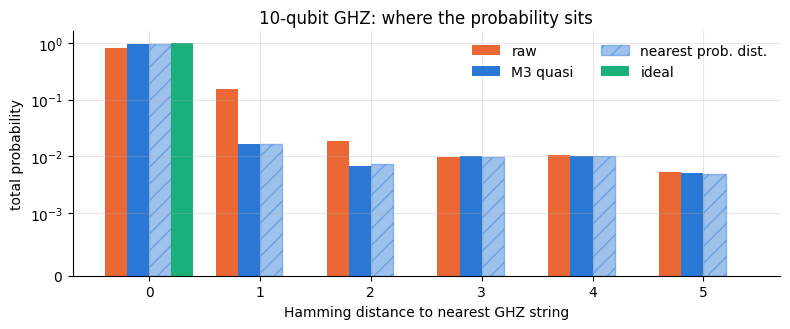

weight at distance 0..5  raw: [0.8024 0.1538 0.0183 0.0098 0.0104 0.0052]
                    mitigated: [0.9516 0.0162 0.0067 0.0102 0.0102 0.005 ]


In [10]:
def by_ghz_distance(dist, n):
    out = np.zeros(n // 2 + 1)
    for b, v in dist.items():
        k = b.count("1"); out[min(k, n - k)] += v
    return out

raw_d = by_ghz_distance({b: v / shots for b, v in countsN.items()}, N)
mit_d = by_ghz_distance(quasiN, N)
prob_d = by_ghz_distance(quasiN.nearest_probability_distribution(), N)
ideal_d = np.zeros(N // 2 + 1); ideal_d[0] = 1

fig, ax = plt.subplots(figsize=(8, 3.4))
x = np.arange(N // 2 + 1); w = 0.2
ax.bar(x - 1.5*w, raw_d, w, color=C_RAW, label="raw")
ax.bar(x - 0.5*w, mit_d, w, color=C_MIT, label="M3 quasi")
ax.bar(x + 0.5*w, prob_d, w, color=C_MIT, alpha=0.45, hatch="//", edgecolor=C_MIT, label="nearest prob. dist.")
ax.bar(x + 1.5*w, ideal_d, w, color=C_IDEAL, label="ideal")
ax.set_yscale("symlog", linthresh=1e-3); ax.set_xticks(x)
ax.set_xlabel("Hamming distance to nearest GHZ string"); ax.set_ylabel("total probability")
ax.set_title(f"{N}-qubit GHZ: where the probability sits"); ax.legend(frameon=False, ncol=2)
plt.tight_layout(); plt.show()
print("weight at distance 0..5  raw:", np.round(raw_d, 4))
print("                    mitigated:", np.round(mit_d, 4))

## 6. Direct vs iterative solvers, and the Hamming distance

This section follows [Advanced usage](https://qiskit.github.io/qiskit-addon-mthree/advanced.html) [5]. `apply_correction(..., method=...)` accepts three values:

* `"direct"`: builds the reduced matrix $\tilde A$ (dense, $n_{\text{obs}}^2$ memory) and solves it with LU. The cost is $O(n_{\text{obs}}^3)$.
* `"iterative"`: GMRES with a Jacobi preconditioner. The products $\tilde A x$ are computed on the fly (OpenMP-parallel C code), so the
  matrix is never stored. The cost is $O(n_{\text{obs}}^2)$ per iteration. Only a few iterations are needed, because $\tilde A$ is close to the identity.
* `"auto"` (default): selects `"direct"` when $n_{\text{obs}} \le$ `iter_threshold` and the matrix fits in half of the free memory.
  `iter_threshold` is 4096 by default; it is set in the `M3Mitigation` constructor.

`details=True` returns the time, the dimension and the number of iterations. To get many distinct bitstrings, we use a uniform superposition
(`H` on every qubit). This is the worst case for M3, because $n_{\text{obs}}\approx\min(2^N, \text{shots})$.

  N  n_obs | direct (s)    <Z..Z> |  iter (s) iters    <Z..Z>
  6     64 |      0.000   0.00157 |     0.002     3   0.00151
  8    256 |      0.001   0.00942 |     0.002     3   0.00907
  9    512 |      0.005   0.01306 |     0.007     3   0.01252
 10   1024 |      0.017  -0.01412 |     0.026     3  -0.01333
 11   2047 |      0.057   0.01315 |     0.113     4   0.01282


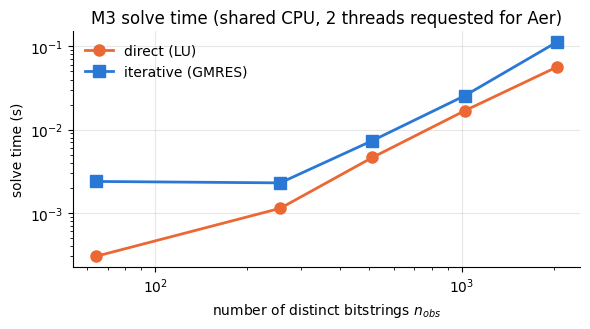

In [11]:
rows = []
for n in [6, 8, 9, 10, 11]:
    qc = QuantumCircuit(n); qc.h(range(n)); qc.measure_all()
    tqc = transpile(qc, sim, optimization_level=1, seed_transpiler=3)
    mp = mthree.utils.final_measurement_mapping(tqc)
    mit.cals_from_system(mp, shots=10_000, async_cal=False)
    cts = sim.run(tqc, shots=16_000).result().get_counts()
    row = [n, len(cts)]
    for meth in ["direct", "iterative"]:
        q, d = mit.apply_correction(cts, mp, method=meth, details=True)
        row += [d["time"], d.get("iterations"), q.expval()]
    rows.append(row)
print(f"{'N':>3} {'n_obs':>6} | {'direct (s)':>10} {'<Z..Z>':>9} | {'iter (s)':>9} {'iters':>5} {'<Z..Z>':>9}")
for n, nobs, td, _, ed, ti, it, ei in rows:
    print(f"{n:>3} {nobs:>6} | {td:10.3f} {ed:9.5f} | {ti:9.3f} {it:>5} {ei:9.5f}")

r = np.array([[x[1], x[2], x[5]] for x in rows], dtype=float)
fig, ax = plt.subplots(figsize=(6, 3.4))
ax.loglog(r[:, 0], r[:, 1], "o-", color=C_RAW, lw=2, ms=8, label="direct (LU)")
ax.loglog(r[:, 0], r[:, 2], "s-", color=C_MIT, lw=2, ms=8, label="iterative (GMRES)")
ax.set_xlabel("number of distinct bitstrings $n_{obs}$"); ax.set_ylabel("solve time (s)")
ax.set_title("M3 solve time (shared CPU, 2 threads requested for Aer)"); ax.legend(frameon=False)
plt.tight_layout(); plt.show()

Both solvers give the same result within the tolerance `tol` (1e-4 by default). The iterative solver becomes faster as $n_{\text{obs}}$ grows.
The exact timings depend on the CPU load and on the number of OpenMP threads (`OMP_NUM_THREADS`).

**Hamming-distance truncation.** `distance=d` keeps only the elements of $\tilde A$ between bitstrings that differ in at most $d$ bits.
`reduced_cal_matrix(counts, qubits, distance)` returns this matrix, so we can measure its sparsity. `distance=N` means no truncation.
`apply_correction` also accepts `distance=-1` for no truncation, but `reduced_cal_matrix` does not.

In [12]:
n = 10
qc = QuantumCircuit(n); qc.h(range(n)); qc.measure_all()
tqc = transpile(qc, sim, optimization_level=1, seed_transpiler=3)
mp = mthree.utils.final_measurement_mapping(tqc)
cts = sim.run(tqc, shots=16_000).result().get_counts()
print(f"{'distance':>8} {'nonzero frac':>12} {'<Z^10>':>10} {'<Z0Z1>':>10}")
for d in [0, 1, 2, 3, 5, n]:
    M, _ = mit.reduced_cal_matrix(cts, [mp[k] for k in sorted(mp)], distance=d)   # needs a list, not a dict
    q = mit.apply_correction(cts, mp, distance=d, method="direct")
    print(f"{d:>8} {np.count_nonzero(M)/M.size:12.3f} {q.expval():10.5f} {q.expval(zstr(n,[0,1])):10.5f}")

distance nonzero frac     <Z^10>     <Z0Z1>
       0        0.001   -0.00575    0.00175
       1        0.011   -0.01502    0.00253
       2        0.055   -0.01390    0.00274
       3        0.172   -0.01412    0.00276
       5        0.623   -0.01411    0.00276
      10        1.000   -0.01411    0.00276


`distance=0` keeps only the diagonal. After the column renormalization, this is the identity, so the result is the raw distribution.
At $d\approx 2$–$3$ the result has converged, and the matrix is still sparse. This is the reason for the default $d=\min(N,3)$.

## 7. Balanced vs independent (vs marginal) calibrations

`cals_from_system(method=...)` has three calibration methods ([Balanced calibrations](https://qiskit.github.io/qiskit-addon-mthree/balanced.html) [6]):

| method | circuits | what is measured |
|---|---|---|
| `"independent"` (default on simulators) | $2N$ | each qubit alone, prepared in $|0\rangle$ and in $|1\rangle$ |
| `"balanced"` (default for other backends) | $\approx N$–$2N$ bit patterns (16 for $N=10$) from a Hadamard-matrix generator (`mthree.generators.HadamardGenerator`), all qubits measured at the same time | each qubit is in $|0\rangle$ in half of the circuits and in $|1\rangle$ in the other half, so the calibration averages over the states of the *other* qubits |
| `"marginal"` | 2 | all qubits in $|0\rangle$, then all qubits in $|1\rangle$ |

Balanced calibrations are the default for backends that are not simulators. They have two advantages:

* they measure all qubits at the same time, as the real experiment does, so crosstalk and measurement-induced effects are included on average;
* they divide the shots evenly between the $|0\rangle$ and $|1\rangle$ preparations. For balanced calibrations, `shots` is the **total** per state, divided over the circuits of the generator.

In this Aer noise model, the readout errors are independent and uncorrelated, so all three methods should agree within the shot noise.
On devices with correlated or state-dependent readout errors, the differences can be important.

independent:  20 circuits,  1.91 s | mean fidelity 0.9830 | <Z^10> = 0.9370 ± 0.0100 | <Z0Z1> = 0.9874


   balanced:  16 circuits,  2.74 s | mean fidelity 0.9831 | <Z^10> = 0.9342 ± 0.0099 | <Z0Z1> = 0.9814


   marginal:   2 circuits,  1.99 s | mean fidelity 0.9829 | <Z^10> = 0.9392 ± 0.0100 | <Z0Z1> = 0.9893


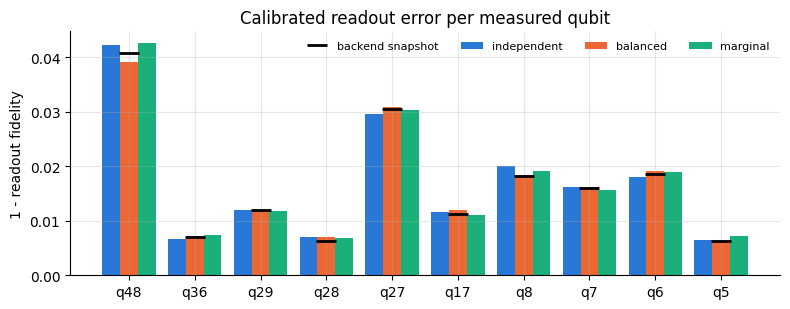

In [13]:
qubits = list(mapN.values())
cal_res = {}
for meth in ["independent", "balanced", "marginal"]:
    m = mthree.M3Mitigation(sim)
    t0 = time.perf_counter()
    jobs = m.cals_from_system(qubits, shots=20_000, method=meth, async_cal=False)
    dt = time.perf_counter() - t0
    ncirc = sum(len(j.circuits()) if hasattr(j, "circuits") else 0 for j in jobs)
    q = m.apply_correction(countsN, mapN, return_mitigation_overhead=True)
    cal_res[meth] = np.array(m.readout_fidelity(qubits))
    print(f"{meth:>11}: {ncirc:3d} circuits, {dt:5.2f} s | mean fidelity {cal_res[meth].mean():.4f} "
          f"| <Z^10> = {q.expval('Z'*N):.4f} ± {q.stddev():.4f} | <Z0Z1> = {q.expval(zstr(N,[0,1])):.4f}")

fig, ax = plt.subplots(figsize=(8, 3.2))
x = np.arange(len(qubits)); w = 0.27
for k, (meth, col) in enumerate(zip(cal_res, [C_MIT, C_RAW, C_IDEAL])):
    ax.bar(x + (k - 1) * w, 1 - cal_res[meth], w, color=col, label=meth)
ax.plot(x, ro_err[qubits], "k_", ms=14, mew=2, label="backend snapshot")
ax.set_xticks(x, [f"q{q}" for q in qubits]); ax.set_ylabel(r"1 - readout fidelity")
ax.set_title("Calibrated readout error per measured qubit"); ax.legend(frameon=False, ncol=4, fontsize=8)
plt.tight_layout(); plt.show()

### Saving, loading and faulty qubits

Calibrations can be saved and loaded again with `cals_to_file` / `cals_from_file` (JSON with a timestamp) ([Saving and loading calibration data](https://qiskit.github.io/qiskit-addon-mthree/cal_io.html) [7]).
They can also be set directly from matrices with `cals_from_matrices`. A qubit with $P(0|1)\ge P(0|0)$ appears in `mit.faulty_qubits`.
`apply_correction` gives a warning when such a qubit is used. The `FakeTorino` snapshot has one such qubit.

In [14]:
with tempfile.TemporaryDirectory() as tmp:
    fn = os.path.join(tmp, "torino_cals.json")
    mit.cals_to_file(fn)
    mit_loaded = mthree.M3Mitigation()                 # no backend needed to *apply* cals
    mit_loaded.cals_from_file(fn)
print("loaded cals timestamp:", mit_loaded.cal_timestamp, "| shots:", mit_loaded.cal_shots)
print("same <Z^10> from loaded cals:", round(mit_loaded.apply_correction(countsN, mapN).expval(), 6),
      "vs", round(mit.apply_correction(countsN, mapN).expval(), 6), "from the in-memory cals")

bad = int(ro_err.argmax())
mit.cals_from_system([bad], shots=4000, async_cal=False)
print(f"qubit {bad}: A1 =", np.array2string(mit.single_qubit_cals[bad], precision=3).replace("\n", ""),
      "| faulty_qubits =", mit.faulty_qubits)

loaded cals timestamp: 2026-10-16T16:49:43.941965+00:00 | shots: 10000
same <Z^10> from loaded cals: 0.938552 vs 0.938552 from the in-memory cals


qubit 86: A1 = [[0.434 0.557] [0.566 0.443]] | faulty_qubits = [86]


## 8. Using M3 with `SamplerV2` results

Primitive results do not contain a single `Counts` object. A `SamplerV2` job returns a `PrimitiveResult` with one `SamplerPubResult` per PUB.
Each `SamplerPubResult` holds one `BitArray` per classical register (`measure_all()` names it `meas`). The steps for M3 are:

1. Transpile to the target **before** sampling (ISA circuits). Get the mapping with `final_measurement_mapping`.
2. Get the counts with `pub_result.data.meas.get_counts()`, or with `get_counts(loc=i)` for one point of a parameter sweep.
3. Pass a **list** of counts, together with either a list of mappings (one per counts dict) or one *flat list* of qubits for all of them.
   A single mapping *dict* is **not** applied to all of them; it raises `Length of counts does not match length of qubits`.
   The result is a `QuasiCollection` ([Using distribution collections](https://qiskit.github.io/qiskit-addon-mthree/collections.html) [9]). Its `expval`/`stddev` return arrays over the collection,
   and `expval_and_stddev` returns a list of `(value, std)` tuples.

Here the Aer `SamplerV2` runs a parametrized GHZ-like circuit: $R_y(\theta)$ on qubit 0, followed by the
CNOT chain. Ideally, $\langle Z_0 Z_{N-1}\rangle = 1$ and $\langle Z_0\rangle = \cos\theta$.

BitArray shape: (9,) | shots: 8000 | bits: 10
QuasiCollection 9
expval_and_stddev on a collection gives a list of tuples: [(np.float64(0.932), np.float64(0.016)), (np.float64(0.929), np.float64(0.016)), (np.float64(0.923), np.float64(0.016))] ...


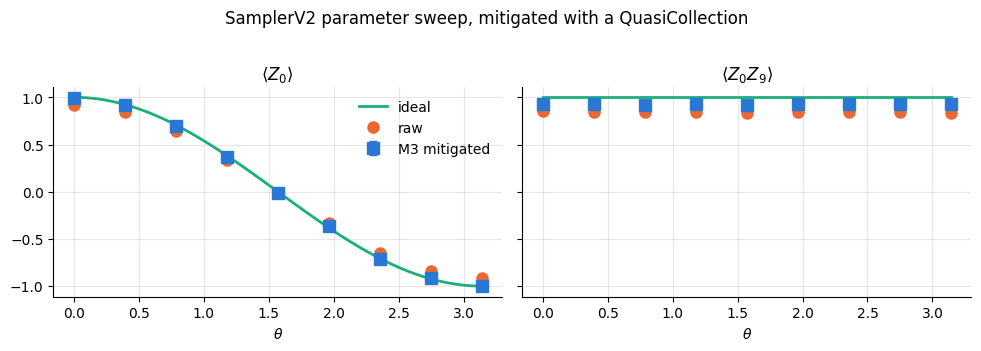

In [15]:
theta = Parameter("θ")
qc = QuantumCircuit(N); qc.ry(theta, 0)
for i in range(N - 1):
    qc.cx(i, i + 1)
qc.measure_all()
isa = transpile(qc, sim, optimization_level=3, seed_transpiler=7)
map_s = mthree.utils.final_measurement_mapping(isa)
mit.cals_from_system(map_s, shots=20_000, async_cal=False)

thetas = np.linspace(0, np.pi, 9)
sampler = AerSamplerV2.from_backend(sim, seed=11)
pub_res = sampler.run([(isa, thetas[:, None])], shots=8000).result()[0]
bits = pub_res.data.meas
print("BitArray shape:", bits.shape, "| shots:", bits.num_shots, "| bits:", bits.num_bits)

counts_list = [bits.get_counts(loc=i) for i in range(len(thetas))]
qubit_list = [map_s[k] for k in sorted(map_s)]            # flat list: broadcast to every counts dict
quasis = mit.apply_correction(counts_list, qubit_list, return_mitigation_overhead=True)   # -> QuasiCollection
print(type(quasis).__name__, len(quasis))

z0 = zstr(N, [0]); z0zl = zstr(N, [0, N - 1])
raw_coll = mthree.classes.ProbCollection([mthree.classes.ProbDistribution(c) for c in counts_list])
m_z0, s_z0 = quasis.expval(z0), quasis.stddev()     # arrays over the sweep
r_z0 = raw_coll.expval(z0)
m_zz, s_zz = quasis.expval(z0zl), quasis.stddev()
print("expval_and_stddev on a collection gives a list of tuples:", [tuple(np.round(t, 3)) for t in quasis.expval_and_stddev(z0zl)[:3]], "...")
r_zz = raw_coll.expval(z0zl)

fig, axs = plt.subplots(1, 2, figsize=(10, 3.4), sharey=True)
tt = np.linspace(0, np.pi, 100)
for ax, (rv, mv, sv, ideal, ttl) in zip(axs, [(r_z0, m_z0, s_z0, np.cos(tt), r"$\langle Z_0\rangle$"),
                                             (r_zz, m_zz, s_zz, np.ones_like(tt), rf"$\langle Z_0 Z_{{{N-1}}}\rangle$")]):
    ax.plot(tt, ideal, color=C_IDEAL, lw=2, label="ideal")
    ax.plot(thetas, rv, "o", color=C_RAW, ms=8, label="raw")
    ax.errorbar(thetas, mv, yerr=sv, fmt="s", color=C_MIT, ms=8, capsize=3, label="M3 mitigated")
    ax.set_xlabel(r"$\theta$"); ax.set_title(ttl)
axs[0].legend(frameon=False)
plt.suptitle("SamplerV2 parameter sweep, mitigated with a QuasiCollection", y=1.02)
plt.tight_layout(); plt.show()

## 9. Summary, notes and references

* Readout noise acts as $\tilde p = A p$ with a $2^N\times2^N$ assignment matrix. Direct inversion has exponential cost. **M3** solves only in the subspace of
  *observed* bitstrings. It builds the matrix elements on the fly from 1-qubit calibrations, renormalizes the columns, and truncates at Hamming distance $d$ (default $\min(N,3)$).
* Workflow: transpile → `final_measurement_mapping` → `M3Mitigation(backend).cals_from_system(mapping)` → `apply_correction(counts, mapping)` →
  `QuasiDistribution.expval_and_stddev(...)` or `.nearest_probability_distribution()`.
* `method="auto"` selects LU (`direct`) for small problems and matrix-free GMRES (`iterative`) above `iter_threshold`. GMRES needs only a few iterations.
* `balanced` calibrations (default for backends that are not simulators) use $\approx N$–$2N$ circuits that measure all qubits together. `independent` (default on simulators) uses $2N$ single-qubit circuits, and `marginal` uses 2.
* M3 corrects only **readout** errors. Gate errors remain: the mitigated GHZ $\langle Z^{\otimes10}\rangle$ stays below 1. Combine M3 with gate-error mitigation, such as zero-noise extrapolation (ZNE) or probabilistic error cancellation (PEC), as needed.

**Notes on the installed version (mthree 3.0.0)**

* `cals_from_system` is **asynchronous by default** (`async_cal=True`). It returns immediately, and the first access to `single_qubit_cals` waits. Use `async_cal=False` for timing.
* The default calibration method depends on `backend.configuration().simulator`, or on `"fake"` in the backend name: `independent` on simulators, `balanced` otherwise.
* For `balanced`, `shots` is the total number of shots per prepared state, divided over the circuits of the generator.
* `utils.expval(counts, [op1, op2])` expects **one operator per distribution**. Several operators on one dict raise `M3Error`. Call it once per operator, or use a collection.
* `reduced_cal_matrix(counts, qubits, distance)` accepts only a *list* of qubits (in clbit order). With a mapping dict it raises a `TypeError`, unlike `apply_correction`. It also does not accept `distance=-1` (`OverflowError`).
* A list of counts with a single mapping dict raises `M3Error`, because the dict is not applied to each counts dict. Pass a flat list of qubits or a list of dicts.
* Operator strings use bitstring order: the leftmost character is the highest classical bit.
* `stddev()` / `expval_and_stddev()` raise `M3Error: Quasi-dist is missing mitigation overhead` if `apply_correction` was called without `return_mitigation_overhead=True`. The bound is $\sqrt{\gamma^2/\text{shots}}$, the same for every operator.
* `stddev()` is an *upper bound* that includes the mitigation overhead. The measured spread is smaller (Section 5).
* Every `SamplerV2`-style result works in the same way. M3 needs only the counts dicts from `BitArray.get_counts()` and the measurement mapping.

**References** (`mthree` documentation pages)

1. Basic usage: <https://qiskit.github.io/qiskit-addon-mthree/basic.html>
2. Using M3 with transpiled circuits: <https://qiskit.github.io/qiskit-addon-mthree/transpiled.html>
3. Obtaining expectation values: <https://qiskit.github.io/qiskit-addon-mthree/expvals.html>
4. Error analysis: <https://qiskit.github.io/qiskit-addon-mthree/error.html>
5. Advanced usage: <https://qiskit.github.io/qiskit-addon-mthree/advanced.html>
6. Balanced calibrations: <https://qiskit.github.io/qiskit-addon-mthree/balanced.html>
7. Saving and loading calibration data: <https://qiskit.github.io/qiskit-addon-mthree/cal_io.html>
8. Converting to probabilities: <https://qiskit.github.io/qiskit-addon-mthree/probs.html>
9. Using distribution collections: <https://qiskit.github.io/qiskit-addon-mthree/collections.html>
10. API reference, `mthree.M3Mitigation`: <https://qiskit.github.io/qiskit-addon-mthree/stubs/mthree.M3Mitigation.html>
11. API reference, `mthree.classes.QuasiDistribution`: <https://qiskit.github.io/qiskit-addon-mthree/stubs/mthree.classes.QuasiDistribution.html>
12. API reference, `mthree.utils.final_measurement_mapping`: <https://qiskit.github.io/qiskit-addon-mthree/stubs/mthree.utils.final_measurement_mapping.html>